# SMPTS — Segmentation Method for Physically Touching Soybean Images (reproduction)

**Paper:** *SMPTS: Segmentation Method for Physically Touching Soybean Images*, ICIVC 2024, DOI: [10.1109/icivc61627.2024.10837290](https://doi.org/10.1109/icivc61627.2024.10837290) (pp. 177–182).
**Code:** MIT-licensed author repository [`Great-Devil-1024/An-image-segmentation-method-for-the-physical-touching-soybean-seeds`](https://github.com/Great-Devil-1024/An-image-segmentation-method-for-the-physical-touching-soybean-seeds) at commit `d4a2377ce61243f28af69161bfd507b3a3adfde2` (the abstract also cites Code Ocean capsule [9219546/v1](https://codeocean.com/capsule/9219546/tree/v1) under MIT).

**Scope (partial demonstration).** This notebook runs the released SMPTS pipeline on the **two 3072×2048 physically-touching soybean test images bundled in the repository** (`src/*.bmp`) and produces the individual **227×227 seed crops**, exactly as `main.cpp` does. It does **not** reproduce the paper's Jetson TX2 accuracy/speed benchmark, and a two-image run says nothing about the published dataset-level accuracy (abstract: >99% overall, ~53 ms/seed).

**⚠ AI-assisted translation.** The authors released C++ (OpenCV 3.4.8, Windows/Ubuntu). This notebook is an **AI-assisted translation of that C++ into Python/OpenCV; the authors did not provide this Python implementation.** The committed C++ cannot run unmodified: `MSRCR_Function.h:666-671` writes a 32-bit-float image to `.bmp` (unsupported → throws) and then applies `cvtColor(BGR2GRAY)` to the 1-channel result (throws); `External_matrix.h:64` resizes a 3-channel ROI into a 1-channel target (throws if reached); `main.cpp` hardcodes the author's local paths. Each deviation is documented at the cell where it applies; the numerical operations themselves are ported 1:1. Untested behavior of the original beyond the executed example is not guaranteed.
（日本語）このノートブックは著者公開の C++ 実装を Python/OpenCV へ AI 翻訳したものです。原著論文の完全な再現ではなく、リポジトリ同梱の 2 枚のテスト画像に対する部分デモンストレーションです。実行は CPU のみで可能です。

## Runtime selection and how to run

**Select Runtime → Change runtime type → CPU** (the method is classical OpenCV image processing; no GPU/CUDA is used anywhere in the pinned repository, and a GPU would not change the result). Then **Runtime → Run all**.

Expected: ~1–3 min total on a free Colab CPU runtime, including ~38 MB of image downloads. All downloads and computation stay inside this Colab VM under `/content`; nothing is fetched from a private API.
（日本語）ランタイムは CPU を選択してください。全セルを実行すると数分で完了します（画像ダウンロード約 38 MB を含む）。

In [ ]:
import sys, platform
import numpy as np, cv2

print("python:", sys.version.split()[0], "| numpy:", np.__version__, "| opencv:", cv2.__version__)
# SMPTS is classical image processing: CPU only, no torch/CUDA involved.


python: 3.13.16 | numpy: 2.1.3 | opencv: 5.0.0


## Minimal inputs and provenance

Download the **two bundled test BMPs** (dataset bytes → Colab only) from the pinned commit via `raw.githubusercontent.com`, then verify them before use: exact byte size, **git blob SHA-1** (from the pinned commit's tree), and the `BM` signature. Expected shape is 3072×2048×3 (BGR). `main.cpp` reads image names from `path.txt`; we use the same two names in the same order.
（日本語）リポジトリ同梱の 2 枚のテスト画像（3072×2048 BMP）をピン留めしたコミットから Colab 内にダウンロードし、サイズ・git blob SHA-1・BMP シグネチャを検証します。

In [ ]:
import hashlib, urllib.request
from pathlib import Path

SRC = Path("/content/smpts/src"); SRC.mkdir(parents=True, exist_ok=True)
INPUTS = [
    ("Image_20220426214755980.bmp", "73a1768b68f2db622d777a7ef982e464fe973e85", 18874422),
    ("Image_20220430064718171.bmp", "9b0fabf9427efc52607154ee1b2dcd27a31cdea8", 18874422),
]

for name, blob_sha, size in INPUTS:
    url = f"https://raw.githubusercontent.com/Great-Devil-1024/An-image-segmentation-method-for-the-physical-touching-soybean-seeds/d4a2377ce61243f28af69161bfd507b3a3adfde2/src/{name}"
    dst = SRC / name
    if not dst.exists() or dst.stat().st_size != size:
        urllib.request.urlretrieve(url, dst)  # dataset bytes stay inside Colab
    raw = dst.read_bytes()
    assert raw[:2] == b"BM", f"{name}: not a BMP"
    assert len(raw) == size, f"{name}: {len(raw)} bytes, expected {size}"
    sha = hashlib.sha1(b"blob %d\0" % size + raw).hexdigest()  # git blob hash at pinned commit
    assert sha == blob_sha, f"{name}: blob SHA mismatch: {sha}"
    print(f"{name}: {len(raw):,} bytes, git blob {sha[:12]}... OK")

# main.cpp reads names from path.txt (Line_number = 2) and processes them in order.
NAMES = [n for n, _, _ in INPUTS]
print("image order (as in path.txt):", NAMES)

Image_20220426214755980.bmp: 18,874,422 bytes, git blob 73a1768b68f2... OK


Image_20220430064718171.bmp: 18,874,422 bytes, git blob 9b0fabf9427e... OK
image order (as in path.txt): ['Image_20220426214755980.bmp', 'Image_20220430064718171.bmp']


## Input preview

Preview the two original touching-soybean images (downscaled for display; analysis runs at full 3072×2048 resolution). These are the repository's own test inputs, not the paper's full evaluation set.
（日本語）解析に使う 2 枚の元画像（表示は縮小、解析はフル解像度）を確認します。

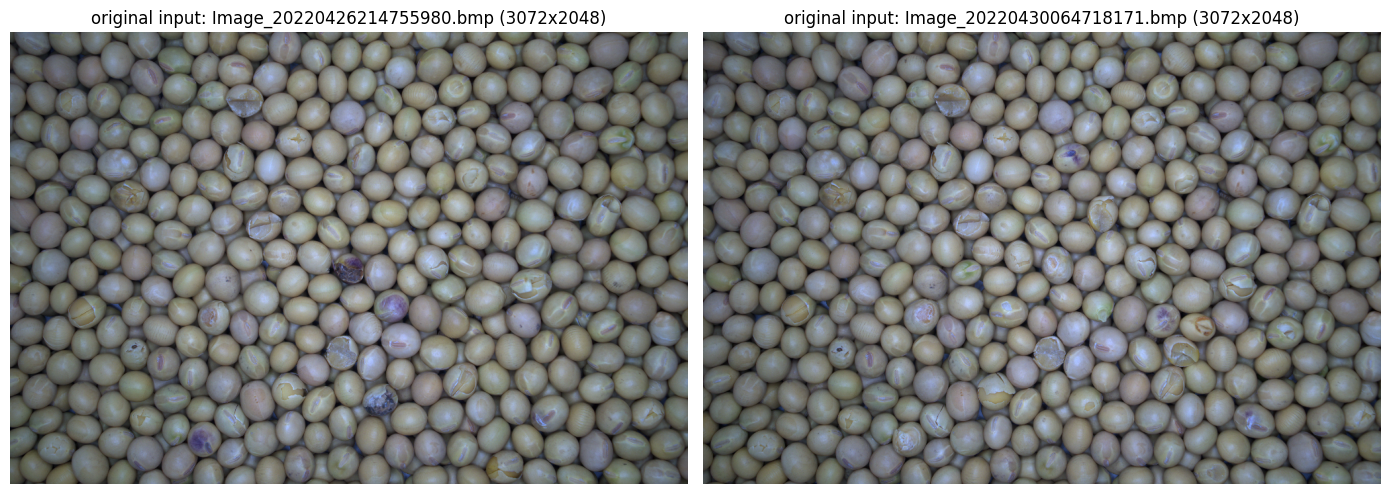

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, NAMES):
    img = cv2.imread(str(SRC / name), cv2.IMREAD_COLOR)  # BGR
    assert img is not None and img.shape == (2048, 3072, 3), (name, None if img is None else img.shape)
    ax.imshow(cv2.cvtColor(cv2.resize(img, (1024, 683)), cv2.COLOR_BGR2RGB))
    ax.set_title(f"original input: {name} (3072x2048)")
    ax.axis("off")
plt.tight_layout(); plt.show()

## MSRCR port (1/2): fast Gaussian pyramid filter

`MSRetinexCR.h` calls `Msrcr::MultiScaleRetinexCR(img, dst, weights=[1/3, 1/3, 1/3], sigmas=[30, 150, 300], gain=128, offset=128)` (restoration factor 6, color gain 2 by default). The author's `FastFilter` (`MSRCR_Function.h:261-298`) filters **in the uint8 domain**: for `filter_size = floor(6σ)//2*2+1 < 10` it applies `cvSmooth(..., CV_GAUSSIAN, fs, fs)` (≡ `cv2.GaussianBlur` with OpenCV's default sigma from ksize); otherwise it recursively downsamples (`cvPyrDown`), filters with σ/2, and upsamples with `INTER_LINEAR`. Ported 1:1 on `uint8` arrays.
（日本語）著者の `FastFilter`（uint8 ドメインのピラミッド再帰 gaussian）をそのまま Python へ移植したものです。

In [ ]:
def fast_filter(img_u8: np.ndarray, sigma: float) -> np.ndarray:
    # exact port of Msrcr::FastFilter (MSRCR_Function.h:261-298)
    if sigma > 300:
        sigma = 300.0
    filter_size = int(np.floor(sigma * 6)) // 2 * 2 + 1
    if filter_size < 3:
        return img_u8
    if filter_size < 10:
        # cvSmooth(img, img, CV_GAUSSIAN, fs, fs) with default sigma from ksize
        return cv2.GaussianBlur(img_u8, (filter_size, filter_size), 0)
    if img_u8.shape[0] < 2 or img_u8.shape[1] < 2:
        return img_u8
    sub = cv2.pyrDown(img_u8)
    sub = fast_filter(sub, sigma / 2.0)
    return cv2.resize(sub, (img_u8.shape[1], img_u8.shape[0]), interpolation=cv2.INTER_LINEAR)

## MSRCR port (2/2): MultiScaleRetinexCR with color restoration

Float32 port of `Msrcr::MultiScaleRetinexCR` (`MSRCR_Function.h:556-774`): log-image minus weighted log-blurred per scale, then per-channel color restoration `log(c/Σ+1)`-style terms, merged with color gain 2. Author quirks preserved exactly:
- the **hardcoded final restore `110*fA + 110`** (`MSRCR_Function.h:757`) — the `gain=128, offset=128` arguments are ignored by the author's code;
- the debug round-trip at lines 666–695 (writes a float image to `/opt/MVS/Data/16.bmp`, reads it back, converts BGR2GRAY, and counts 255-valued pixels to get `rate = count/6291456`, with `6291456 = 3072·2048` hardcoded). As committed this **cannot execute** (float→BMP throws; `cvtColor` on the 1-channel result throws), so we use the minimal in-memory interpretation: saturate the channel sum to uint8 and count the 255s; the hardcoded `6291456` denominator is kept and guarded by an input-shape assertion.
- `cvDiv` zero-divisor semantics (result 0) are reproduced explicitly. For pure-black pixels `log(0) = -inf` and `-inf - (-inf) = NaN`, exactly as the author's C API (`cvLog`/`cvSub`) would produce; the final saturating cast maps NaN→0 just like OpenCV's `cvConvertScale`, so the NumPy warnings are silenced explicitly rather than silently changing the math.
（日本語）MSRCR（色修復付きマルチスケール Retinex）の移植。著者コード固有の仕様（固定の 110/110 復元、デバッグ用 rate 計算）を明示的に再現しています。

In [ ]:
def msrcr_cr(img_bgr: np.ndarray) -> np.ndarray:
    # exact port of Msrcr::MultiScaleRetinexCR (MSRCR_Function.h:556-774), 3-channel uint8 in/out.
    # np.errstate: log(0)=-inf and inf-inf=NaN arise exactly as in the author's C API for
    # pure-black pixels; the final saturating cast maps NaN to 0 like OpenCV cvConvertScale.
    with np.errstate(divide="ignore", invalid="ignore"):
        return _msrcr_cr_impl(img_bgr)


def _msrcr_cr_impl(img_bgr: np.ndarray) -> np.ndarray:
    # exact port of Msrcr::MultiScaleRetinexCR (MSRCR_Function.h:556-774), 3-channel uint8 in/out
    weights = [1.0 / 3, 1.0 / 3, 1.0 / 3]
    sigmas = [30.0, 150.0, 300.0]
    restoration_factor, color_gain = 6.0, 2.0

    fA = np.log(img_bgr.astype(np.float32))          # cvConvert(img, fB); cvLog(fB, fA)
    weight = 0.0
    for w in weights:                                 # author's sequential accumulation
        weight += w
    if weight != 1.0:
        fA = fA * np.float32(weight)                  # cvScale(fA, fA, weight)

    for w, s in zip(weights, sigmas):                 # filter at each scale (uint8 domain, as authored)
        blurred = fast_filter(img_bgr.copy(), s)
        fC = np.log(blurred.astype(np.float32))       # cvConvert(A, fB); cvLog(fB, fC)
        fA = fA - np.float32(w) * fC                  # cvScale(fC, fC, w); cvSub(fA, fC, fA)

    # color restoration (author's BGR channel order)
    fsA = img_bgr[:, :, 0].astype(np.float32)         # cvSplit -> B
    fsB = img_bgr[:, :, 1].astype(np.float32)         #            G
    fsC = img_bgr[:, :, 2].astype(np.float32)         #            R
    fsD = fsA + fsB + fsC                             # cvAdd; cvAdd

    # debug round-trip replacement (MSRCR_Function.h:666-695): saturate to uint8, count 255s
    assert img_bgr.shape[0] * img_bgr.shape[1] == 6291456, "author hardcodes 6291456 = 3072*2048 pixels"
    src_gray = np.clip(fsD, 0, 255).astype(np.uint8)
    rate = float(np.count_nonzero(src_gray == 255)) / 6291456.0

    def cv_div(num, den):                             # cvDiv semantics: 0 where den == 0
        out = np.zeros_like(num)
        np.divide(num, den, out=out, where=den != 0)
        return out

    fsA = np.log(cv_div(fsA, fsD) * np.float32(restoration_factor) + np.float32(1.0))  # cvDiv; +1; cvLog
    fsB = np.log(cv_div(fsB, fsD) * np.float32(restoration_factor) + np.float32(1.0))
    fsC = np.log(cv_div(fsC, fsD) * np.float32(restoration_factor) + np.float32(1.0))
    fsA, fsB, fsC = fsA * np.float32(rate), fsB * np.float32(rate), fsC * np.float32(rate)  # cvConvertScale(..., rate)

    fsD, fsE, fsF = fA[:, :, 0].copy(), fA[:, :, 1].copy(), fA[:, :, 2].copy()  # cvSplit(fA, ...)
    fsD = fsD * fsA * np.float32(color_gain)          # cvMul(..., color_gain)
    fsE = fsE * fsB * np.float32(color_gain)
    fsF = fsF * fsC * np.float32(color_gain)
    fA = cv2.merge([fsD, fsE, fsF])                   # cvMerge -> fA

    out = fA * np.float32(110.0) + np.float32(110.0)  # hardcoded restore (author ignores gain/offset args)
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)  # saturate_cast<uchar>

## Otsu threshold port (with the author's own quirk)

`External_matrix.h:83-89` computes the author's `myOtsu(src_gray)` (`Otsu.h`, between-class variance maximization) and then calls `threshold(src_gray, binary_output, binary_thresh, 255, THRESH_OTSU)` — because `THRESH_OTSU` is set, **OpenCV ignores the passed threshold and computes its own Otsu**, so the custom `myOtsu` value is effectively dead code. We keep both, as authored.
（日本語）`myOtsu` を移植しますが、元コードでは `THRESH_OTSU` フラグ側の大津法が実際の二値化に使われます（その挙動をそのまま維持）。

In [ ]:
def my_otsu(gray_u8: np.ndarray) -> int:
    # exact port of myOtsu (Otsu.h): maximize between-class variance w0*w1*(u0-u1)^2
    pix_count = np.bincount(gray_u8.ravel(), minlength=256).astype(np.float32)
    pix_pro = pix_count / np.float32(gray_u8.size)
    idx = np.arange(256, dtype=np.float32)
    w0 = np.cumsum(pix_pro)
    u0cum = np.cumsum(idx * pix_pro)
    total_u = np.float32(idx @ pix_pro)
    w1 = 1.0 - w0
    with np.errstate(divide="ignore", invalid="ignore"):
        u0 = u0cum / w0
        u1 = (total_u - u0cum) / w1
    delta = w0 * w1 * (u0 - u1) ** 2
    delta[~np.isfinite(delta)] = 0.0
    return int(np.argmax(delta))  # author keeps the first maximum (strictly greater comparison)

## Segmentation port: contours, size rules, erosion of touching regions, 227×227 crops

Port of `thresh_callback` + `thresh_callback_particular_for_watered`-style helper (`External_matrix.h:20-162`). Rules as authored:
- binarize the MSRCR result with Otsu, `findContours(RETR_TREE, CHAIN_APPROX_SIMPLE)`, `approxPolyDP(ε=3)`;
- accept a contour if `(w>95 ∧ h>95) ∨ (w>115 ∧ h>95) ∨ (w>95 ∧ h>115)`;
- **touching regions** (w>300 ∨ h>300): mask the binary image, apply `morphologyEx(op=MORPH_RECT=0)` — in OpenCV `MORPH_RECT == 0 == MORPH_ERODE`, i.e. an **erosion** with a 13×13 rectangular element (preserved as authored) — then per eroded contour with bbox >100×100 crop and resize to 227×227;
- otherwise crop the single seed directly.

Two documented adaptations: (1) the eroded-branch resize keeps the 3-channel ROI (the committed `External_matrix.h:64` declares a 1-channel target and would throw — latent crash); (2) in the eroded branch the author's filled-circle mask `drawing` **accumulates across contours** (declared outside the loop) — preserved as authored. The watershed variant exists in `Watershed.h` but its call is commented out in the committed code, so it is not executed.
（日本語）輪郭抽出・サイズ条件・接触領域の収縮（13×13）・227×227 クロップを元コードどおりに移植します（ウォーターシェッドはコメントアウトされているため実行しません）。

In [ ]:
def thresh_callback_open_operation(mask_binary, msrcr_src, count, out_dir):
    # port of External_matrix.h:20-67 (accumulating 'drawing' kept as authored)
    contours, _ = cv2.findContours(mask_binary, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    drawing = np.zeros(msrcr_src.shape[:2], np.uint8)
    for i, c in enumerate(contours):
        poly = cv2.approxPolyDP(c, 3, True)
        x0, y0, w0, h0 = cv2.boundingRect(poly)
        if w0 > 100 and h0 > 100:
            (cx, cy), radius = cv2.minEnclosingCircle(poly)
            cv2.circle(drawing, (int(round(cx)), int(round(cy))), int(radius), 255, -1)  # accumulates
            dst = msrcr_src.copy()
            dst[drawing == 0] = 0                       # msrcr_src.copyTo(dst, drawing)
            roi = dst[y0:y0 + h0, x0:x0 + w0]
            crop = cv2.resize(roi, (227, 227), interpolation=cv2.INTER_LINEAR)  # adaptation: keep 3 channels
            cv2.imwrite(str(out_dir / f"{count}.bmp"), crop)
            count += 1
    return count


def thresh_callback(msrcr_src, count, out_dir):
    # port of External_matrix.h:70-162
    src_gray = cv2.cvtColor(msrcr_src, cv2.COLOR_BGR2GRAY)
    binary_thresh = my_otsu(src_gray)                   # computed, then superseded by THRESH_OTSU (as authored)
    _, binary_output = cv2.threshold(src_gray, binary_thresh, 255, cv2.THRESH_OTSU)
    cv2.imwrite(str(out_dir / "Binary.bmp"), binary_output)
    contours, _ = cv2.findContours(binary_output, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    accepted = []
    for i, c in enumerate(contours):
        poly = cv2.approxPolyDP(c, 3, True)
        x0, y0, w0, h0 = cv2.boundingRect(poly)
        if (w0 > 95 and h0 > 95) or (w0 > 115 and h0 > 95) or (w0 > 95 and h0 > 115):
            accepted.append((x0, y0, w0, h0))
            if w0 > 300 or h0 > 300:                    # physically touching region
                mask = np.zeros(binary_output.shape, np.uint8)
                cv2.drawContours(mask, contours, i, 255, -1)
                mask_binary = binary_output.copy()
                mask_binary[mask == 0] = 0              # binary_output.copyTo(mask_binary, mask)
                element = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 13))
                mask_binary = cv2.morphologyEx(mask_binary, cv2.MORPH_RECT, element)  # op 0 == MORPH_ERODE
                count = thresh_callback_open_operation(mask_binary, msrcr_src, count, out_dir / "Individual_Seeds")  # author: create_files(file_path, "Individual_Seeds")
            else:                                       # single seed
                mask_drawing = np.zeros(binary_output.shape, np.uint8)  # fresh per contour, as authored
                (cx, cy), radius = cv2.minEnclosingCircle(poly)
                cv2.circle(mask_drawing, (int(round(cx)), int(round(cy))), int(radius), 255, -1, 8, 0)
                dst = msrcr_src.copy()
                dst[mask_drawing == 0] = 0              # msrcr_src.copyTo(dst, mask_drawing)
                roi = dst[y0:y0 + h0, x0:x0 + w0]
                crop = cv2.resize(roi, (227, 227), interpolation=cv2.INTER_LINEAR)
                cv2.imwrite(str(out_dir / "Individual_Seeds" / f"{count}.bmp"), crop)
                count += 1
    return count, accepted, binary_output

## Run SMPTS on both test images (mirrors `main.cpp`)

For each image, in `path.txt` order: create the output folders (`<name>/MSRCR.bmp`, `<name>/Binary.bmp`, `<name>/Individual_Seeds/<n>.bmp`), apply MSRCR, re-read the saved MSRCR image from disk (as `thresh_callback` does), binarize, segment, and crop. The seed counter and the printed total/average timing mirror `main.cpp` (`count_seeds` starts at 1 and is shared across both images).
（日本語）`main.cpp` と同じ順序・同じ出力構成で 2 枚の画像を処理し、個人種子画像（227×227）と計測時間を出力します。

In [ ]:
import time, shutil

ROOT_OUT = Path("/content/smpts_out")
shutil.rmtree(ROOT_OUT, ignore_errors=True)  # idempotent re-runs: clear stale outputs
count_seeds = 1  # main.cpp: count_seeds = 1, shared across images
results = []
t0 = time.perf_counter()
for name in NAMES:
    file_path = ROOT_OUT / name
    (file_path / "Individual_Seeds").mkdir(parents=True, exist_ok=True)
    print(name, "Processing.....")
    img = cv2.imread(str(SRC / name), cv2.IMREAD_COLOR)
    assert img is not None, name
    msrcr_src_path = file_path / "MSRCR.bmp"
    cv2.imwrite(str(msrcr_src_path), msrcr_cr(img))   # MSRetinexCR(): enhance + save
    msrcr_src = cv2.imread(str(msrcr_src_path), cv2.IMREAD_COLOR)  # thresh_callback re-reads from disk
    count_seeds, accepted, binary_output = thresh_callback(msrcr_src, count_seeds, file_path)
    elapsed = time.perf_counter() - t0
    results.append({"image": name, "accepted_contours": len(accepted),
                    "seeds_total_so_far": count_seeds - 1, "elapsed_s": round(elapsed, 2)})
    print(name, "Processing completed.")

running_time = time.perf_counter() - t0
print(f"Total Runing Time: {running_time:.2f} s")       # main.cpp output text preserved (sic)
print(f"The Avarage Time for Segmentation a Individual Soybean Seeds: {running_time / count_seeds:.4f} s")
for r in results:
    print(r)

Image_20220426214755980.bmp Processing.....


Image_20220426214755980.bmp Processing completed.
Image_20220430064718171.bmp Processing.....


Image_20220430064718171.bmp Processing completed.
Total Runing Time: 141.02 s
The Avarage Time for Segmentation a Individual Soybean Seeds: 0.2478 s
{'image': 'Image_20220426214755980.bmp', 'accepted_contours': 284, 'seeds_total_so_far': 285, 'elapsed_s': 70.35}
{'image': 'Image_20220430064718171.bmp', 'accepted_contours': 282, 'seeds_total_so_far': 568, 'elapsed_s': 141.02}


## Segmentation result overlay

Overlay the accepted bounding boxes (green) on the original input for each image — SMPTS's located individual/touching seeds. These are the **pipeline's predictions** from this run, not author-provided ground truth; the paper's accuracy claims are not verified here.
（日本語）入力画像に対し、本実行で検出された個体の外接矩形（緑）を重畳表示します（著者提供の正解ではなく本パイプラインの予測です）。

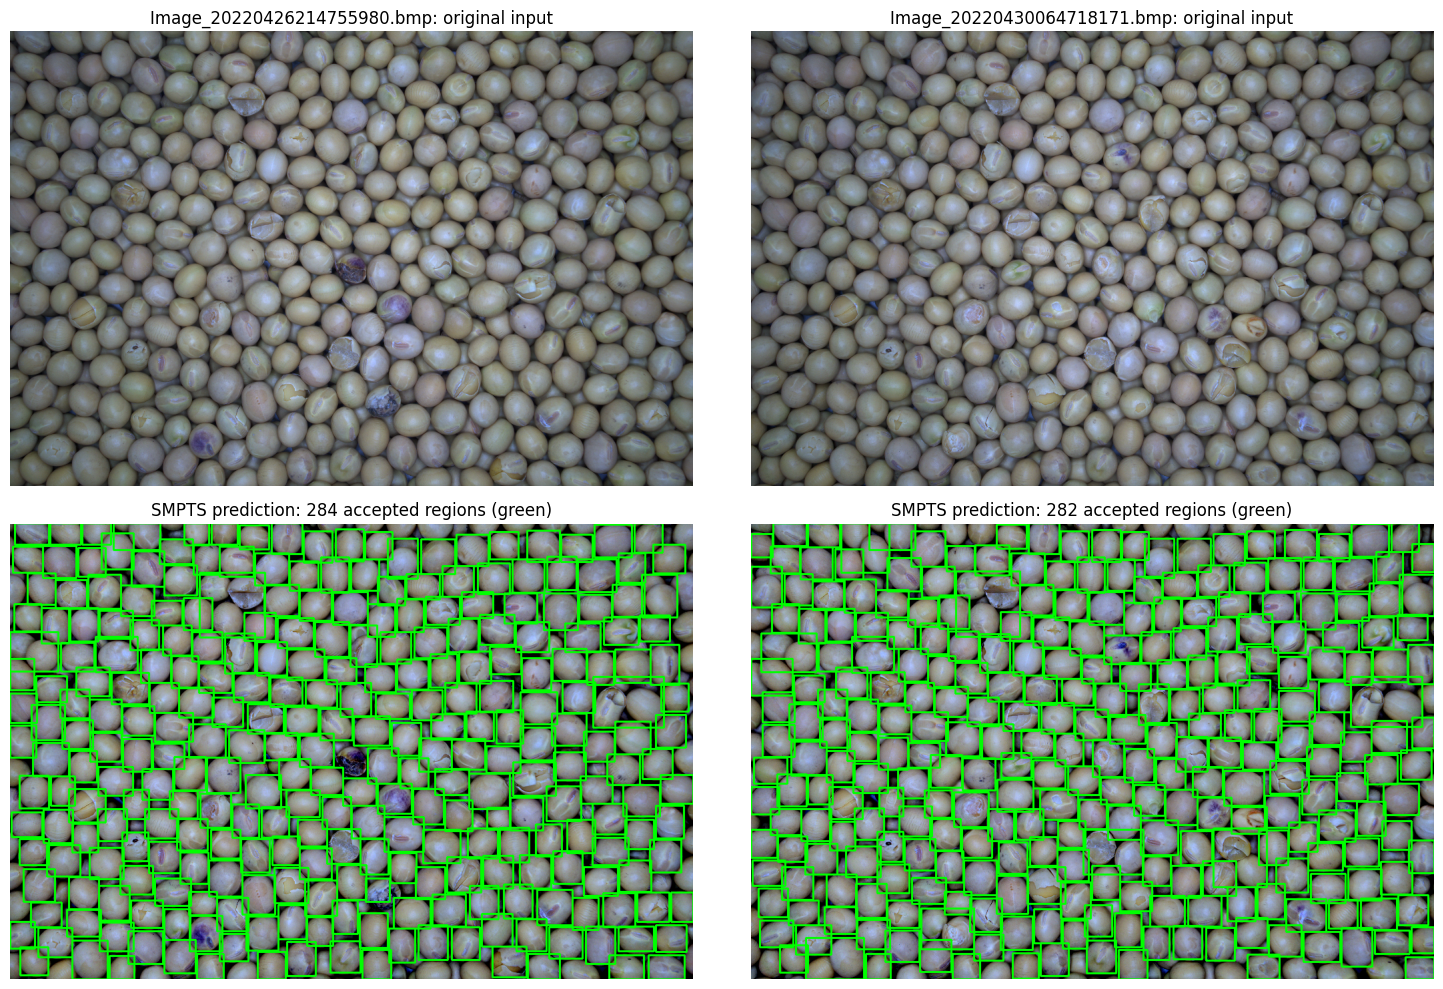

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for col, name in enumerate(NAMES):
    file_path = ROOT_OUT / name
    msrcr_src = cv2.imread(str(file_path / "MSRCR.bmp"), cv2.IMREAD_COLOR)
    binary = cv2.imread(str(file_path / "Binary.bmp"), cv2.IMREAD_GRAYSCALE)
    # re-derive accepted boxes for display (same rules as thresh_callback)
    contours, _ = cv2.findContours(binary, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    vis = cv2.resize(msrcr_src, (1024, 683))
    n_boxes = 0
    for c in contours:
        poly = cv2.approxPolyDP(c, 3, True)
        x0, y0, w0, h0 = cv2.boundingRect(poly)
        if (w0 > 95 and h0 > 95) or (w0 > 115 and h0 > 95) or (w0 > 95 and h0 > 115):
            cv2.rectangle(vis, (x0 * 1024 // 3072, y0 * 683 // 2048),
                          ((x0 + w0) * 1024 // 3072, (y0 + h0) * 683 // 2048), (0, 255, 0), 2)
            n_boxes += 1
    axes[0, col].imshow(cv2.cvtColor(cv2.resize(cv2.imread(str(SRC / name)), (1024, 683)), cv2.COLOR_BGR2RGB))
    axes[0, col].set_title(f"{name}: original input"); axes[0, col].axis("off")
    axes[1, col].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    axes[1, col].set_title(f"SMPTS prediction: {n_boxes} accepted regions (green)"); axes[1, col].axis("off")
plt.tight_layout(); plt.show()

## Intermediate results: MSRCR enhancement and Otsu binary mask

The MSRCR output (contrast/illumination enhancement, `MSRCR.bmp`) and the Otsu-binary mask (`Binary.bmp`) for each test image — the actual intermediate artifacts saved by the pipeline.
（日本語）中間結果：MSRCR による画像強調結果と、大津法による二値マスクを表示します。

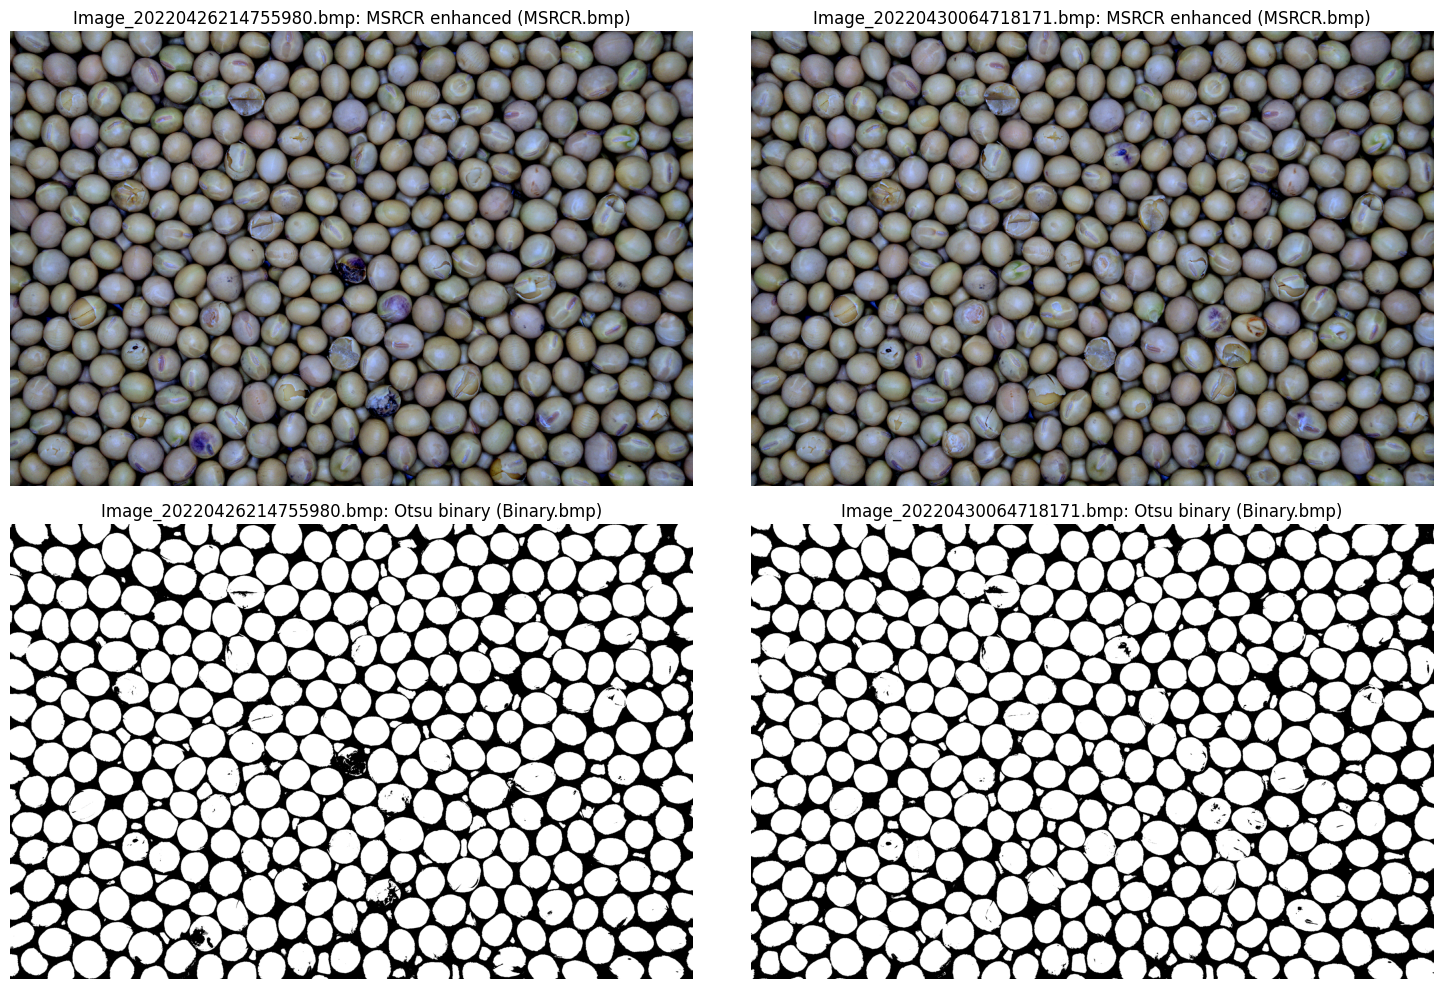

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for col, name in enumerate(NAMES):
    file_path = ROOT_OUT / name
    msrcr_src = cv2.imread(str(file_path / "MSRCR.bmp"), cv2.IMREAD_COLOR)
    binary = cv2.imread(str(file_path / "Binary.bmp"), cv2.IMREAD_GRAYSCALE)
    axes[0, col].imshow(cv2.cvtColor(cv2.resize(msrcr_src, (1024, 683)), cv2.COLOR_BGR2RGB))
    axes[0, col].set_title(f"{name}: MSRCR enhanced (MSRCR.bmp)"); axes[0, col].axis("off")
    axes[1, col].imshow(binary, cmap="gray")
    axes[1, col].set_title(f"{name}: Otsu binary (Binary.bmp)"); axes[1, col].axis("off")
plt.tight_layout(); plt.show()

## Individual seed crops (227×227)

The pipeline's final output: individual seed images resized to 227×227 (`Individual_Seeds/<n>.bmp`), exactly as the repository README describes ("create individual soybean seed images (227x227 pixels)"). The numbering continues across both images, as in `main.cpp`. Shown: the first 8 crops from each image.
（日本語）最終出力である 227×227 の個人種子画像を表示します（番号は main.cpp と同様に両画像で連続）。

Image_20220426214755980.bmp: 285 individual seed crops saved to /content/smpts_out/Image_20220426214755980.bmp/Individual_Seeds
Image_20220430064718171.bmp: 283 individual seed crops saved to /content/smpts_out/Image_20220430064718171.bmp/Individual_Seeds


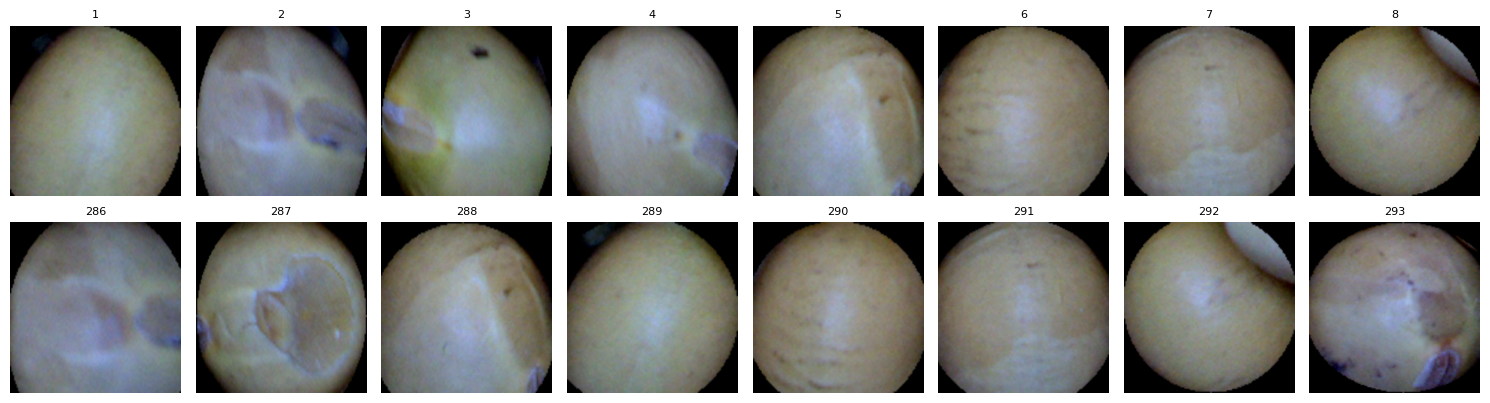

In [ ]:
fig, axes = plt.subplots(2, 8, figsize=(15, 4.2))
for row, name in enumerate(NAMES):
    crops = sorted((ROOT_OUT / name / "Individual_Seeds").glob("*.bmp"), key=lambda p: int(p.stem))
    print(f"{name}: {len(crops)} individual seed crops saved to {ROOT_OUT / name / 'Individual_Seeds'}")
    for k in range(8):
        ax = axes[row, k]
        if k < len(crops):
            ax.imshow(cv2.cvtColor(cv2.imread(str(crops[k])), cv2.COLOR_BGR2RGB))
            ax.set_title(crops[k].stem, fontsize=8)
        ax.axis("off")
plt.tight_layout(); plt.show()

## Results table and CSV export

Small quantitative summary of this run: per-image accepted regions, cumulative seed count, and measured wall time. The CSV is written inside the Colab VM (`/content/smpts_results.csv`) for export. This is a **two-image demonstration**, not the paper's benchmark.
（日本語）本実行の結果（領域数・累計種子数・計測時間）を表と CSV にまとめます。論文のベンチマーク結果ではありません。

In [ ]:
import pandas as pd

df = pd.DataFrame(results)
df["total_running_s"] = round(running_time, 2)
df["avg_time_per_seed_s"] = round(running_time / count_seeds, 4)
print(df.to_string(index=False))
df.to_csv("/content/smpts_results.csv", index=False)
print("saved: /content/smpts_results.csv")

                      image  accepted_contours  seeds_total_so_far  elapsed_s  total_running_s  avg_time_per_seed_s
Image_20220426214755980.bmp                284                 285      70.35           141.02               0.2478
Image_20220430064718171.bmp                282                 568     141.02           141.02               0.2478
saved: /content/smpts_results.csv


## Interpretation, differences from the paper, and limitations

**What was executed:** the released SMPTS pipeline (MSRCR enhancement → Otsu binarization → contour size rules → 13×13 erosion of touching regions → 227×227 crops) on the repository's two bundled 3072×2048 test images, on a CPU Colab runtime.

**Differences from the paper's description (abstract vs. committed code):** the abstract/study flow mentions an adaptive-mean threshold and a median filter; the committed code contains **neither** — it uses Otsu thresholding of the MSRCR-enhanced gray image and a 13×13 erosion, and its watershed module is commented out. We reproduce the **committed code** (the MIT-licensed released artifact) and record this discrepancy; the paper body (pp. 177–182, closed access) was not available to resolve it.

**Known deviations of this port** (all documented above): the unavoidable debug-block interpretation (`rate` via in-memory uint8 saturation), the 3-channel resize fix in the eroded branch, and path adaptations. `myOtsu` is computed but superseded by `THRESH_OTSU`, as in the original. Author attribution of the GitHub repository is unverified (no real-name account; repo dated 2023, paper 2024); the abstract cites a Code Ocean capsule with the same method under MIT.

**Not verified here:** the paper's reported accuracy (>99% overall; per-class ≈ 100%, 99.66%, 96.56%, 99.44%, 99.51%) and ~53 ms/seed on Jetson TX2 — the two bundled images are a demo sample, not the evaluation protocol.

**References:** DOI 10.1109/icivc61627.2024.10837290 · repo commit `d4a2377ce61243f28af69161bfd507b3a3adfde2` · `README.md`, `main.cpp`, `MSRCR_Function.h`, `MSRetinexCR.h`, `Otsu.h`, `External_matrix.h`, `Watershed.h`, `create_file.h`, `create_img.h`.

（日本語）本ノートブックは公開実装の 2 枚のテスト画像での部分再現です。論文本文は閉鎖アクセスのため未確認であり、要旨と実装の差異（適応的平均閾値・メディアンフィルタの有無など）は記録済みです。精度・速度の論文値は本デモでは検証していません。